In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")

FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_parquet("../data/processed/features.parquet")
comp_df = pd.read_csv("../reports/d03_model_comparison.csv")

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]

print(f"Train : {train_df.index.min().date()} -> {train_df.index.max().date()} ({len(train_df)} obs)")
print(f"Val   : {val_df.index.min().date()} -> {val_df.index.max().date()} ({len(val_df)} obs)")
comp_df

Train : 2018-02-01 -> 2022-12-30 (1238 obs)
Val   : 2023-01-03 -> 2024-12-31 (502 obs)


,Modèle,Ordre,AIC,BIC,RMSE (Val),MAE (Val),Dir Acc (%),Ljung-Box p (lag 10),Ljung-Box p (lag 20)
0,Baseline : Naïf Zéro (r_t = 0),-,NaN,NaN,0.009594,0.007109,1.195219,NaN,NaN
1,Baseline : Naïf Persistance (r_{t-1}),-,NaN,NaN,0.013299,0.009725,52.589641,NaN,NaN
2,Baseline : Moyenne Mobile 5j,-,NaN,NaN,0.010469,0.007836,52.191235,NaN,NaN
3,Baseline : Moyenne Mobile 20j,-,NaN,NaN,0.009793,0.007248,53.386454,NaN,NaN
4,ARIMA (XLF seul),"(2, 0, 2)",-6585.377928,-6554.664970,0.009679,0.007206,47.410359,2.678831e-10,2.977083e-10
5,SARIMAX (XLF + SPY_{t-1}),"(2, 0, 2)",-6583.069366,-6547.237583,0.009687,0.007213,48.007968,3.482076e-10,3.704129e-10


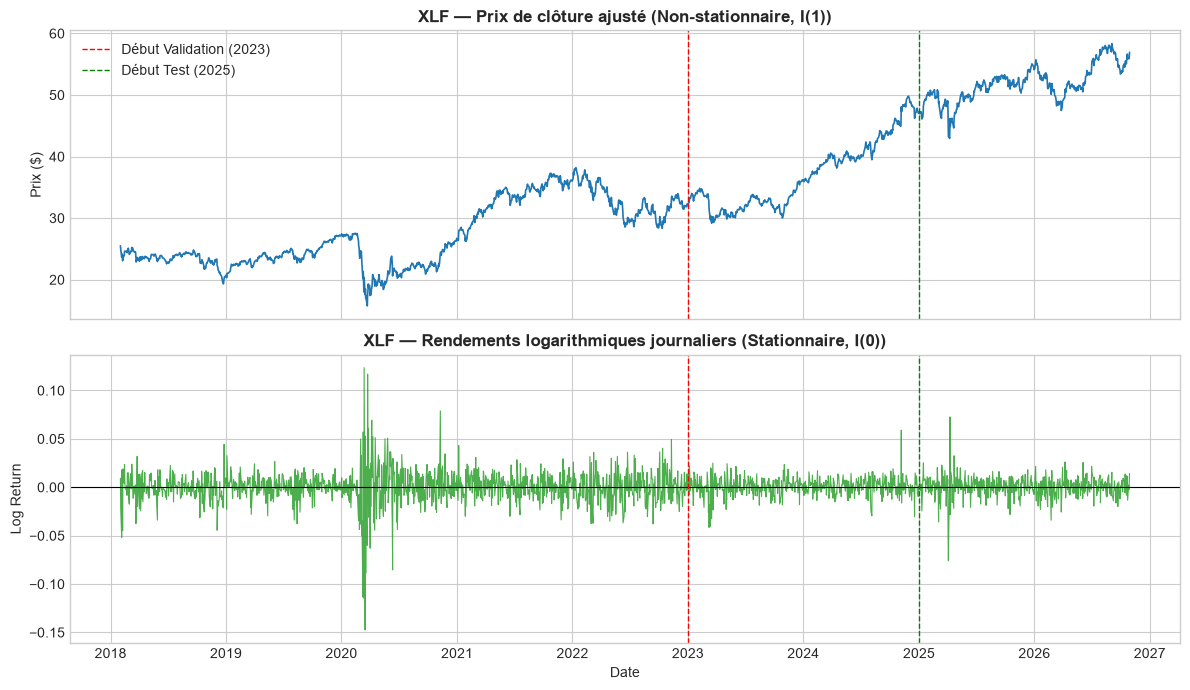

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Prix brut XLF
axes[0].plot(df.index, df["close_xlf"], color="#1f77b4", lw=1.2)
axes[0].axvline(pd.Timestamp("2023-01-01"), color="red", ls="--", lw=1, label="Début Validation (2023)")
axes[0].axvline(pd.Timestamp("2025-01-01"), color="green", ls="--", lw=1, label="Début Test (2025)")
axes[0].set_title("XLF — Prix de clôture ajusté (Non-stationnaire, I(1))", fontweight="bold")
axes[0].set_ylabel("Prix ($)")
axes[0].legend()

# Log Returns XLF
axes[1].plot(df.index, df["r_xlf"], color="#2ca02c", lw=0.8, alpha=0.85)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].axvline(pd.Timestamp("2023-01-01"), color="red", ls="--", lw=1)
axes[1].axvline(pd.Timestamp("2025-01-01"), color="green", ls="--", lw=1)
axes[1].set_title("XLF — Rendements logarithmiques journaliers (Stationnaire, I(0))", fontweight="bold")
axes[1].set_ylabel("Log Return")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/d03_stationarity_xlf.png", dpi=150)
plt.show()

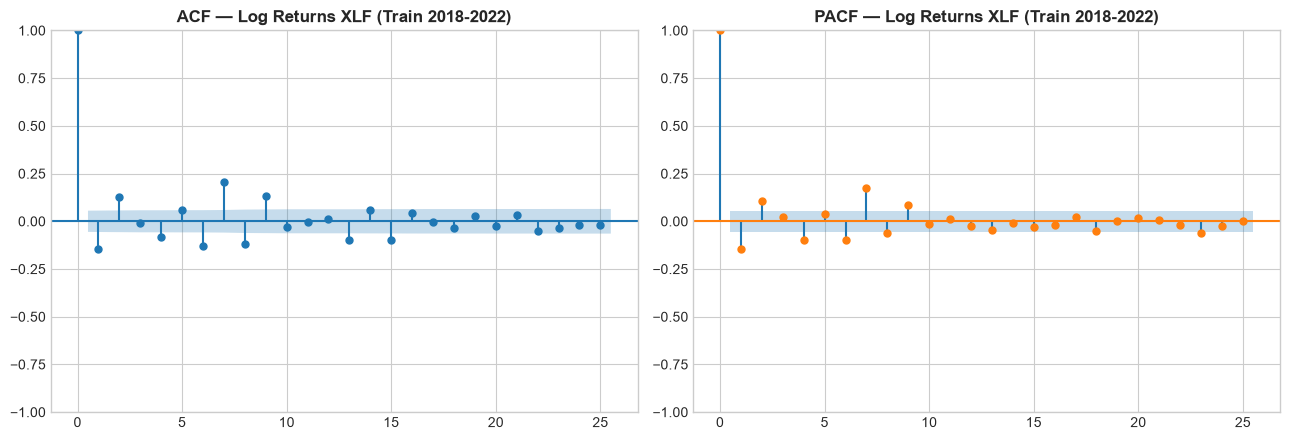

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_acf(train_df["r_xlf"], lags=25, ax=axes[0], color="#1f77b4")
axes[0].set_title("ACF — Log Returns XLF (Train 2018-2022)", fontweight="bold")

plot_pacf(train_df["r_xlf"], lags=25, ax=axes[1], color="#ff7f0e", method="ywm")
axes[1].set_title("PACF — Log Returns XLF (Train 2018-2022)", fontweight="bold")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/d03_acf_pacf_xlf.png", dpi=150)
plt.show()

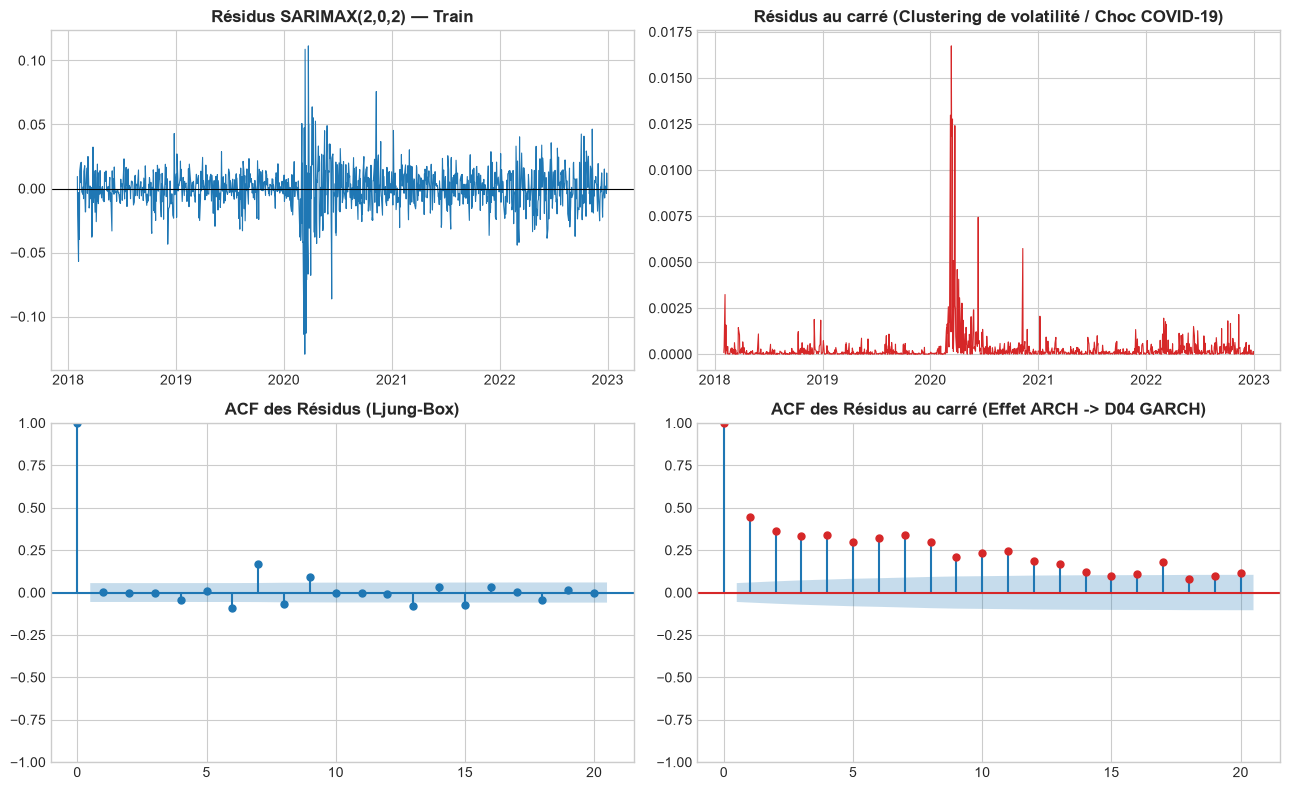

In [4]:
train_y = train_df["r_xlf"].to_numpy()
train_x = train_df[["r_spy_lag1"]].to_numpy()

sarimax_res = SARIMAX(
    train_y, exog=train_x, order=(2, 0, 2), trend="c",
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)

resid = pd.Series(sarimax_res.resid, index=train_df.index)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 1. Résidus dans le temps
axes[0, 0].plot(resid.index, resid, color="#1f77b4", lw=0.8)
axes[0, 0].axhline(0, color="black", lw=0.8)
axes[0, 0].set_title("Résidus SARIMAX(2,0,2) — Train", fontweight="bold")

# 2. Résidus au carré (Volatility Clustering)
axes[0, 1].plot(resid.index, resid**2, color="#d62728", lw=0.8)
axes[0, 1].set_title("Résidus au carré (Clustering de volatilité / Choc COVID-19)", fontweight="bold")

# 3. ACF des résidus
plot_acf(resid, lags=20, ax=axes[1, 0], color="#1f77b4")
axes[1, 0].set_title("ACF des Résidus (Ljung-Box)", fontweight="bold")

# 4. ACF des résidus au carré (Justification de GARCH - D04)
plot_acf(resid**2, lags=20, ax=axes[1, 1], color="#d62728")
axes[1, 1].set_title("ACF des Résidus au carré (Effet ARCH -> D04 GARCH)", fontweight="bold")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/d03_sarimax_residuals_diagnostic.png", dpi=150)
plt.show()

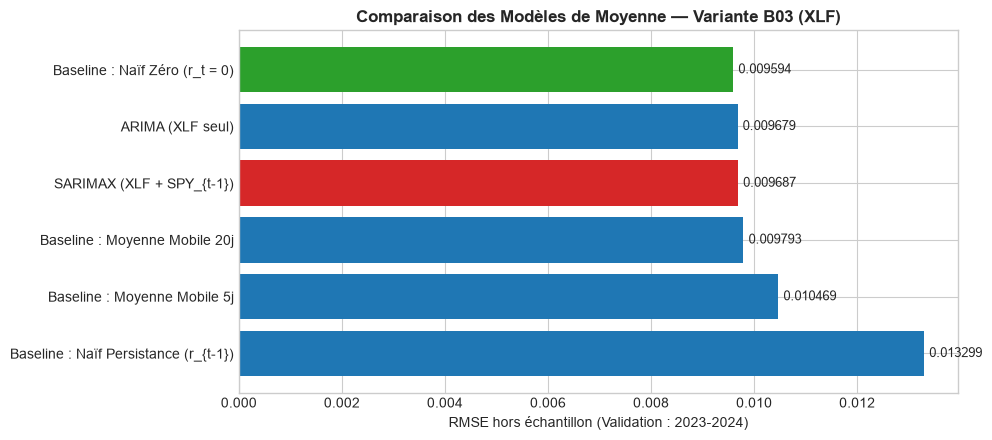

In [5]:
plot_df = comp_df.sort_values("RMSE (Val)", ascending=True)

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#2ca02c" if "Naïf Zéro" in m else ("#d62728" if "SARIMAX" in m else "#1f77b4") for m in plot_df["Modèle"]]

bars = ax.barh(plot_df["Modèle"], plot_df["RMSE (Val)"], color=colors)
ax.set_xlabel("RMSE hors échantillon (Validation : 2023-2024)")
ax.set_title("Comparaison des Modèles de Moyenne — Variante B03 (XLF)", fontweight="bold")
ax.invert_yaxis()

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.0001, bar.get_y() + bar.get_height()/2, f"{w:.6f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/d03_rmse_comparison.png", dpi=150)
plt.show()

## Conclusions du Livrable D03 (Variante B03 : XLF vs SPY)

1. **Stationnarité validée ($I(1) \to I(0)$) :** Les tests ADF ($p = 0{,}6017$) et KPSS ($p = 0{,}01$) confirment la non-stationnarité des prix bruts XLF. Le passage aux rendements logarithmiques garantit la stationnarité ($ADF\ p = 0{,}0000$, $KPSS\ p = 0{,}10$).
2. **Réponse à la question scientifique B03 (ARIMA vs SARIMAX) :** L'ajout de la variable exogène retardée $SPY_{t-1}$ n'améliore pas la prévision linéaire de la moyenne :
   * Le coefficient de $SPY_{t-1}$ ($-0{,}0351$) est statistiquement non significatif ($p = 0{,}4285 > 0{,}05$).
   * **ARIMA(2,0,2)** présente un AIC ($-6585{,}38$), un BIC ($-6554{,}66$) et un RMSE Validation ($0{,}009679$) légèrement meilleurs que **SARIMAX(2,0,2)** ($-6583{,}07$ / $-6547{,}24$ / $0{,}009687$).
   * La baseline **Naïf Zéro** ($\hat{r}_t = 0$) obtient le plus faible RMSE ($0{,}009594$), résultat cohérent avec l'**Hypothèse d'Efficience des Marchés (EMH)** sur deux ETFs américains très liquides.
3. **Diagnostic des résidus & Transition vers D04 (GARCH) :** Le test de Ljung-Box ($p = 0{,}0000$) et l'ACF fortement significative des **résidus au carré** mettent en évidence un fort *volatility clustering* (notamment lors du choc COVID-19 de 2020). La modélisation linéaire de la moyenne ne suffit donc pas : le **Livrable D04** modélisera la volatilité conditionnelle via **GARCH(1,1)**, la **VaR (99 %)** et l'**Expected Shortfall**.